# Reto AgroCebada FIRA 2026
## Libreta 02 · Ingeniería Fenológica y Espacial

> *"Traducimos píxeles a agronomía: estrés hídrico, senescencia y acumulación térmica."*

### Sección del Reporte que alimenta esta libreta
| Sección del Reporte | Contenido generado aquí |
|---|---|
| **Metodología** | Construcción de bloques temáticos, variables fenológicas, integración espacial |

### Objetivos de esta libreta
1. Extraer variables climáticas (CHIRPS/ERA5) y topográficas (INEGI) desde rásteres GeoTIFF.
2. Construir variables fenológicas interpretables: AUC, Delta máximo, P90, IQR.
3. Integrar los 4 bloques temáticos: Suelo/Térmico, Vegetación, Agua y Entorno.
4. Exportar la matriz de características lista para la Libreta 03.

### Alcance temporal
Ciclo agrícola **abril–octubre de 2025**. Análisis retrospectivo del ciclo completo.

### Dependencia
Esta libreta lee los artefactos generados por la **Libreta 01** y los datos crudos del `DataSet.zip`.

### 🔧 Notas de la versión corregida (qué cambió respecto a la versión anterior)

| # | Problema en la versión anterior | Corrección |
|---|---|---|
| 1 | **El clima mensual nunca entró a la matriz.** El filtro buscaba `'2025-04'` (con guion) pero las columnas se llaman `PREC_2025_04_mean` (con guion bajo): solo pasaban elevación y pendiente. | Filtro con `'2025_04'` + **aserción** que exige 7 meses × (PREC, Tmin, Tmax) + 2 topográficas. Si falla, la libreta se detiene. |
| 2 | La documentación decía "media zonal **ponderada por área**" y "mediana espacial ponderada por intersección"; el código usa `all_touched=True` (promedio simple de los píxeles que tocan el polígono). | Documentación corregida; el resumen JSON refleja el método real. |
| 3 | `mes_maximo` se guardaba como texto (`'2025-07'`) y el filtro numérico de la Libreta 03 lo descartaba. | Se guarda como **número de mes** (4–10). |
| 4 | Algunos índices de las listas no existen en el dataset (`mndwi`, `msavi` en Básico, `savi` en PRO) y se omitían en silencio; faltaban `lai` y `msavi` de PRO. | Listas corregidas por sensor y **aviso explícito** si un índice se omite. |
| 5 | Las variables físicas descritas en el reporte (integral del dosel, mes pico de NDVI, cociente de estrés) no existían como columnas. | Bloque nuevo `fisica__*`. |
| 6 | Se generaban cientos de avisos de fragmentación del DataFrame. | Se acumulan columnas en un diccionario y se concatenan una vez. |
| 7 | La extracción no manejaba explícitamente NoData (−9999). | Se usa el NoData del archivo (o −9999) y se descartan valores ≤ −9000. |

> **Cambio en el conjunto de variables:** al corregir las listas de índices, el bloque *Vegetación* pasa de 7 a 9 variables (se añaden `lai` y `msavi` de PRO). Los resultados de la Libreta 03 **cambiarán** respecto a corridas anteriores; es lo esperado.

In [ ]:
# ============================================================
# CONFIGURACIÓN MAESTRA - Entorno
# ============================================================
import os
from pathlib import Path

EN_COLAB = True  # <-- Cambiar a False si el evaluador lo corre en su PC local (GitHub)

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/Reto_AgroCebada_2026')
else:
    # Usa el directorio actual (la raíz del repositorio clonado de GitHub)
    BASE = Path(os.getcwd())

CARPETAS = {
    'raw':           BASE / 'data' / 'raw',
    '01_calidad':    BASE / 'data' / '01_calidad',
    '02_fenologia':  BASE / 'data' / '02_fenologia',
    '03_validacion': BASE / 'data' / '03_validacion',
    '04_shap':       BASE / 'data' / '04_shap',
    '05_final':      BASE / 'data' / '05_final',
    'models':        BASE / 'models',
    'artifacts':     BASE / 'artifacts', # <-- Aquí irán los archivos del Dashboard
    'reports':       BASE / 'reports',
}

for carpeta in CARPETAS.values():
    carpeta.mkdir(parents=True, exist_ok=True)

# Funciones helper
def guardar_csv(df, nombre, carpeta='raw'):
    ruta = CARPETAS[carpeta] / nombre
    df.to_csv(ruta, index=False, encoding='utf-8-sig')
    print(f"✅ Guardado: {ruta}")
    return ruta

def cargar_csv(nombre, carpeta='raw', **kwargs):
    ruta = CARPETAS[carpeta] / nombre
    assert ruta.exists(), f"❌ No existe: {ruta}"
    df = pd.read_csv(ruta, **kwargs)
    print(f"📂 Cargado: {nombre} ({df.shape[0]} filas × {df.shape[1]} cols)")
    return df

def guardar_figura(fig, nombre, carpeta='reports'):
    ruta = CARPETAS[carpeta] / nombre
    fig.savefig(ruta, dpi=200, bbox_inches='tight')
    print(f"✅ Gráfico guardado: {ruta}")
    return ruta

def listar_archivos(carpeta='raw'):
    ruta = CARPETAS[carpeta]
    archivos = sorted(ruta.iterdir()) if ruta.exists() else []
    if not archivos:
        print(f"📁 Carpeta '{carpeta}' vacía")
    else:
        print(f"📁 Carpeta '{carpeta}': {len(archivos)} archivos")
        for a in archivos:
            tamaño = a.stat().st_size
            unidad = 'MB' if tamaño > 1e6 else 'KB' if tamaño > 1e3 else 'B'
            valor = tamaño / 1e6 if tamaño > 1e6 else tamaño / 1e3 if tamaño > 1e3 else tamaño
            print(f"   • {a.name} ({valor:.1f} {unidad})")
    return archivos

# Parámetros del proyecto
INICIO = '2025-04-01'
FIN = '2025-10-31'
MESES = [f'2025-{m:02d}' for m in range(4, 11)]
NOMBRES_MESES = ['Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre']

print("✅ Configuración Drive completada")
print(f"   Ventana temporal: {INICIO} a {FIN}")

Mounted at /content/drive
✅ Configuración Drive completada
   Ventana temporal: 2025-04-01 a 2025-10-31


In [ ]:
# ============================================================
# 1. CARGA DE DATOS DESDE DRIVE
# ============================================================
RAW = CARPETAS['raw'] / 'extraido' / 'DATASET_RETO_AGRO_2026'

# Tabla Maestra
ruta_maestro = RAW / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv'
df_maestro = pd.read_csv(ruta_maestro)
df_maestro['ID_POLIGONO'] = df_maestro['ID_POLIGONO'].str.strip()
columnas_vacias = [c for c in df_maestro.columns if c.startswith('Unnamed:') and df_maestro[c].isna().all()]
if columnas_vacias:
    df_maestro = df_maestro.drop(columns=columnas_vacias)

# Dataset PRO (Planet)
df_pro = pd.read_csv(RAW / 'Conjunto_datos_PRO_AgroCebada.csv', dtype={'ID_POLIGONO': str})
df_pro['ID_POLIGONO'] = df_pro['ID_POLIGONO'].str.strip()

# Dataset Básico (Sentinel-2 / Landsat)
df_basico = pd.read_csv(RAW / 'Conjunto_datos_BASICO_AgroCebada2026.csv', dtype={'ID_POLIGONO': str})
df_basico['ID_POLIGONO'] = df_basico['ID_POLIGONO'].str.strip()

# Shapefile - Búsqueda recursiva para evitar problemas con subcarpetas extras
import geopandas as gpd
shp_files = list(RAW.rglob('*.shp')) + list(RAW.rglob('*.SHP'))
# Eliminar duplicados si los hay
shp_files = list(set(shp_files))

assert len(shp_files) == 1, f"Se esperaba 1 .shp, se encontraron {len(shp_files)} en {RAW}: {shp_files}"
gdf_parcelas = gpd.read_file(shp_files[0])

# Normalizar columna ID
columnas_id = [c for c in gdf_parcelas.columns if 'ID_POL' in c.upper()]
if columnas_id:
    gdf_parcelas = gdf_parcelas.rename(columns={columnas_id[0]: 'ID_POLIGONO'})
gdf_parcelas['ID_POLIGONO'] = gdf_parcelas['ID_POLIGONO'].astype(str).str.strip()

# Separación entrenamiento/predicción
df_entrenamiento = df_maestro[df_maestro['CONJUNTO'] == 'ENTRENAMIENTO'].copy()
df_prediccion = df_maestro[df_maestro['CONJUNTO'] == 'PREDICCION'].copy()

print(f"✅ Maestro: {len(df_maestro)} parcelas")
print(f"✅ PRO: {len(df_pro)} capturas")
print(f"✅ Básico: {len(df_basico)} capturas")
print(f"✅ Shapefile: {len(gdf_parcelas)} geometrías")
print(f"✅ Entrenamiento: {len(df_entrenamiento)} | Predicción: {len(df_prediccion)}")

✅ Maestro: 197 parcelas
✅ PRO: 47804 capturas
✅ Básico: 107666 capturas
✅ Shapefile: 197 geometrías
✅ Entrenamiento: 138 | Predicción: 59


### 🗺️ Extracción de Variables Climáticas y Topográficas

Las fuentes ráster del reto incluyen:
- **CHIRPS**: precipitación mensual (mm/mes), ~5 km (0.05°).
- **CHIRTS-ERA5**: temperatura mínima y máxima mensual (°C), ~5 km (0.05°).
- **INEGI CEM 4.0**: elevación (m s.n.m.) y pendiente (grados), 120 m.

**Método de extracción (tal como está implementado):** `rasterstats.zonal_stats(..., stats="mean", all_touched=True)` tras reproyectar las parcelas al CRS de cada ráster. Es el **promedio simple de los píxeles que tocan el polígono**; *no* pondera por área de intersección. Con píxeles climáticos de ~5 km, la mayoría de las parcelas caen en uno o pocos píxeles, de modo que parcelas vecinas reciben valores casi idénticos. Si se quisiera ponderar por área habría que usar otra herramienta (por ejemplo `exactextract`) y documentarlo.

**NoData:** se usa el valor declarado en cada archivo (o −9999 si no lo trae) y, como salvaguarda, cualquier media ≤ −9000 se convierte en `NaN`.

In [ ]:
# ============================================================
# 2. EXTRACCIÓN RÁSTER (Clima + Topografía)
# ============================================================
!pip install -q rasterstats rasterio

import rasterio
from rasterstats import zonal_stats
import zipfile
import numpy as np
import pandas as pd

print("1. Localizando los ZIPs internos de clima y topografía...")
RAW_INTERNO = CARPETAS['raw'] / 'extraido' / 'DATASET_RETO_AGRO_2026'
if not RAW_INTERNO.exists():
    RAW_INTERNO = CARPETAS['raw'] / 'extraido'

carpeta_raster = CARPETAS['raw'] / 'raster_extraidos'
carpeta_raster.mkdir(parents=True, exist_ok=True)

zips_internos = list(RAW_INTERNO.glob('*.zip'))
zips_clima_topo = [z for z in zips_internos
                   if any(k in str(z).lower() for k in ['chirps', 'topografia', 'temperatura', 'inegi', 'cem'])]
if not zips_clima_topo:
    print("⚠️ No se encontraron los ZIPs de clima/topografía. ZIPs disponibles:")
    for z in zips_internos:
        print(f"   - {z.name}")
for archivo in zips_clima_topo:
    print(f"   - Descomprimiendo: {archivo.name}")
    with zipfile.ZipFile(archivo, 'r') as zip_ref:
        zip_ref.extractall(carpeta_raster)

print("\n2. Buscando archivos .tif...")
archivos_tif = sorted(carpeta_raster.glob('**/*.tif'))
print(f"   Se encontraron {len(archivos_tif)} GeoTIFF (esperados: 146 = 48 PREC + 48 Tmin + 48 Tmax + 2 topografía).")
assert len(archivos_tif) > 0, "No hay archivos .tif; revisa la estructura de los ZIP."
if len(archivos_tif) != 146:
    print("   ⚠️ El número de GeoTIFF difiere de lo documentado; revisa duplicados o archivos faltantes.")

if gdf_parcelas.crs is None:
    gdf_parcelas = gdf_parcelas.set_crs('EPSG:4326')

print("\n3. Extrayendo estadísticas zonales (promedio simple, all_touched=True)...")
columnas_raster = {}
cache_crs = {}                       # reproyectar las parcelas una sola vez por CRS
errores = []
for tif in archivos_tif:
    nombre_columna = tif.stem.replace(' ', '_') + '_mean'
    try:
        with rasterio.open(tif) as src:
            raster_crs = src.crs
            nodata_archivo = src.nodata
        if raster_crs is None:
            errores.append((tif.name, 'sin CRS'))
            continue
        clave = raster_crs.to_string()
        if clave not in cache_crs:
            cache_crs[clave] = gdf_parcelas.to_crs(raster_crs)
        nodata = nodata_archivo if nodata_archivo is not None else -9999
        stats = zonal_stats(cache_crs[clave], str(tif), stats='mean', all_touched=True, nodata=nodata)
        valores = np.array([s['mean'] if (s and s.get('mean') is not None) else np.nan for s in stats], dtype=float)
        valores[valores <= -9000] = np.nan          # salvaguarda: NoData documentado = -9999
        columnas_raster[nombre_columna] = valores
    except Exception as e:
        errores.append((tif.name, str(e)))

ids_parcelas = gdf_parcelas['ID_POLIGONO'].astype(str).str.strip().reset_index(drop=True)
df_clima_topo = pd.concat([ids_parcelas.to_frame('ID_POLIGONO'), pd.DataFrame(columnas_raster)], axis=1)

print(f"\n✅ Extracción completada: {df_clima_topo.shape[1] - 1} variables, {len(df_clima_topo)} parcelas.")
if errores:
    print(f"⚠️ {len(errores)} archivos con error: {errores[:5]}")
pct_nan = df_clima_topo.drop(columns='ID_POLIGONO').isna().mean().sort_values(ascending=False)
print(f"   Columnas con NaN: {(pct_nan > 0).sum()} (máximo {pct_nan.iloc[0] * 100:.1f}% en {pct_nan.index[0]})")

ruta_clima = CARPETAS['raw'] / 'datos_clima_topografia.csv'
df_clima_topo.to_csv(ruta_clima, index=False)
print(f"   Guardado en: {ruta_clima}")

1. Localizando los ZIPs internos de clima y topografía...
   - Descomprimiendo: Reto_AgroCebada_CHIRPS_Precipitacion_2022_2025.zip
   - Descomprimiendo: Reto_AgroCebada_Temperatura_2022_2025_RECORTADA_CHIRPS.zip
   - Descomprimiendo: Reto_AgroCebada_Topografia_INEGI_CEM4.zip

2. Buscando archivos .tif...
   Se encontraron 146 GeoTIFF (esperados: 146 = 48 PREC + 48 Tmin + 48 Tmax + 2 topografía).

3. Extrayendo estadísticas zonales (promedio simple, all_touched=True)...

✅ Extracción completada: 146 variables, 197 parcelas.
   Columnas con NaN: 0 (máximo 0.0% en PREC_2022_01_mean)
   Guardado en: /content/drive/MyDrive/Reto_AgroCebada_2026/data/raw/datos_clima_topografia.csv


In [ ]:
# ============================================================
# 3. FILTRAR CLIMA A LA VENTANA DEL CICLO AGRÍCOLA (abril-octubre 2025)
# ============================================================
df_clima = df_clima_topo.copy()
df_clima['ID_POLIGONO'] = df_clima['ID_POLIGONO'].astype(str).str.strip()

cols_clima = [c for c in df_clima.columns if c != 'ID_POLIGONO']
print(f"Variables climáticas/topográficas totales: {len(cols_clima)}")

# CORREGIDO: los nombres de columna usan guion bajo (PREC_2025_04_mean), no guion (2025-04).
meses_cultivo = [f'2025_{m:02d}' for m in range(4, 11)]
cols_validas = [c for c in cols_clima
                if any(m in c for m in meses_cultivo) or 'Elevacion' in c or 'Pendiente' in c]

n_prec = sum(c.startswith('PREC_') for c in cols_validas)
n_tmin = sum(c.startswith('Tmin_') for c in cols_validas)
n_tmax = sum(c.startswith('Tmax_') for c in cols_validas)
n_topo = sum(('Elevacion' in c) or ('Pendiente' in c) for c in cols_validas)
print(f"Variables en la ventana del ciclo: {len(cols_validas)}  "
      f"(PREC={n_prec}, Tmin={n_tmin}, Tmax={n_tmax}, topografía={n_topo})")

# ASERCIÓN: si el filtro vuelve a dejar fuera el clima, la libreta se detiene en lugar de continuar en silencio.
assert (n_prec, n_tmin, n_tmax) == (7, 7, 7), (
    f"Se esperaban 7 meses de PREC, Tmin y Tmax (abril-octubre 2025); hay {(n_prec, n_tmin, n_tmax)}. "
    f"Revisa los nombres de columna: {cols_clima[:5]}")
assert n_topo == 2, f"Se esperaban 2 variables topográficas (elevación y pendiente); hay {n_topo}."

df_clima_filtrado = df_clima[['ID_POLIGONO'] + sorted(cols_validas)].copy().set_index('ID_POLIGONO')

print("\nColumnas seleccionadas:")
for c in df_clima_filtrado.columns:
    print(f"   • {c}")
guardar_csv(df_clima_filtrado.reset_index(), 'clima_topografia_filtrado.csv', '02_fenologia')

Variables climáticas/topográficas totales: 146
Variables en la ventana del ciclo: 23  (PREC=7, Tmin=7, Tmax=7, topografía=2)

Columnas seleccionadas:
   • Elevacion_INEGI_CEM4_120m_mean
   • PREC_2025_04_mean
   • PREC_2025_05_mean
   • PREC_2025_06_mean
   • PREC_2025_07_mean
   • PREC_2025_08_mean
   • PREC_2025_09_mean
   • PREC_2025_10_mean
   • Pendiente_INEGI_CEM4_120m_grados_mean
   • Tmax_2025_04_mean
   • Tmax_2025_05_mean
   • Tmax_2025_06_mean
   • Tmax_2025_07_mean
   • Tmax_2025_08_mean
   • Tmax_2025_09_mean
   • Tmax_2025_10_mean
   • Tmin_2025_04_mean
   • Tmin_2025_05_mean
   • Tmin_2025_06_mean
   • Tmin_2025_07_mean
   • Tmin_2025_08_mean
   • Tmin_2025_09_mean
   • Tmin_2025_10_mean
✅ Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia/clima_topografia_filtrado.csv


PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia/clima_topografia_filtrado.csv')

In [ ]:
# ============================================================
# 3b. VARIABLES CLIMÁTICAS DERIVADAS ("físicas")
# Son agregados simples de los promedios MENSUALES (CHIRPS/CHIRTS, ~5 km). No son series diarias:
# no equivalen a grados día ni a la evapotranspiración de Hargreaves (que requiere radiación y rango térmico diario).
# ============================================================
def _cols(prefijo, meses):
    return [f'{prefijo}_2025_{m:02d}_mean' for m in meses]

MESES_CICLO = range(4, 11)       # abril-octubre
MESES_LLENADO = range(7, 10)     # julio-septiembre (llenado de grano; ventana definida por el equipo)

d = df_clima_filtrado
prec_ciclo = d[_cols('PREC', MESES_CICLO)].sum(axis=1, skipna=False)
prec_llenado = d[_cols('PREC', MESES_LLENADO)].sum(axis=1, skipna=False)
tmax_ciclo = d[_cols('Tmax', MESES_CICLO)].mean(axis=1)
tmin_ciclo = d[_cols('Tmin', MESES_CICLO)].mean(axis=1)
tmax_llenado = d[_cols('Tmax', MESES_LLENADO)].mean(axis=1)

df_fisica_clima = pd.DataFrame({
    'fisica__prec_acum_abr_oct': prec_ciclo,
    'fisica__prec_acum_jul_sep': prec_llenado,
    'fisica__tmax_media_abr_oct': tmax_ciclo,
    'fisica__tmin_media_abr_oct': tmin_ciclo,
    'fisica__amplitud_termica_abr_oct': tmax_ciclo - tmin_ciclo,
    # Cociente heurístico de estrés: precipitación jul-sep / Tmax media jul-sep (NO es Hargreaves)
    'fisica__cociente_estres_jul_sep': prec_llenado / tmax_llenado.where(tmax_llenado > 0),
}, index=d.index)

print(f"✅ Variables físicas de clima: {df_fisica_clima.shape[1]}")
print(df_fisica_clima.describe().T[['count', 'mean', 'min', 'max']].round(2).to_string())

✅ Variables físicas de clima: 6
                                  count    mean     min      max
fisica__prec_acum_abr_oct         197.0  963.87  704.80  1459.14
fisica__prec_acum_jul_sep         197.0  443.34  316.84   763.74
fisica__tmax_media_abr_oct        197.0   23.67   23.25    24.01
fisica__tmin_media_abr_oct        197.0   12.88   11.42    13.48
fisica__amplitud_termica_abr_oct  197.0   10.79   10.15    11.83
fisica__cociente_estres_jul_sep   197.0   19.26   13.87    33.99


### Construcción de Variables Fenológicas

Para cada índice satelital, extraemos métricas que capturan la dinámica del cultivo a lo largo del ciclo:

| Métrica | Interpretación agronómica (aproximada) |
|---|---|
| **AUC** | Suma de los valores mensuales (mediana mensual del promedio espacial por captura). Proxy de acumulación del dosel; **no** incorpora radiación solar. |
| **Delta máximo** | Mayor cambio absoluto entre meses consecutivos (velocidad de crecimiento/senescencia). |
| **P90** | Percentil 90 de la serie mensual (pico de vigor). |
| **IQR** | Rango intercuartílico de la serie mensual (variabilidad intra-ciclo). |
| **Mes del máximo** | Número de mes (4–10) en que ocurre el máximo; fenología aproximada. |

**Notas:**
- Se calculan sobre series **mensuales** que construimos nosotros (mediana de las capturas de cada mes); los CSV originales traen una fila por captura. Es una decisión de agregación del equipo, no una restricción de los datos.
- Se exige un mínimo de 3 meses con dato por parcela; las parcelas con menos meses quedan con `NaN` en esa variable.

In [ ]:
# ============================================================
# 4. CONSTRUCCIÓN DE VARIABLES FENOLÓGICAS
# ============================================================
from scipy.stats import spearmanr

# Preparar datos satelitales con ventana del ciclo
df_basico['fecha_captura'] = pd.to_datetime(df_basico['fecha_captura'], format='%d/%m/%Y')
df_pro['fecha_captura'] = pd.to_datetime(df_pro['fecha_captura'], format='%d/%m/%Y')

ventana_inicio = pd.Timestamp(INICIO)
ventana_fin = pd.Timestamp(FIN)

df_basico_ventana = df_basico[
    (df_basico['fecha_captura'] >= ventana_inicio) &
    (df_basico['fecha_captura'] <= ventana_fin)
].copy()
df_basico_ventana['mes'] = df_basico_ventana['fecha_captura'].dt.to_period('M').astype(str)

df_pro_ventana = df_pro[
    (df_pro['fecha_captura'] >= ventana_inicio) &
    (df_pro['fecha_captura'] <= ventana_fin)
].copy()
df_pro_ventana['mes'] = df_pro_ventana['fecha_captura'].dt.to_period('M').astype(str)

# Identificar índices disponibles
sufijos = ['_promedio', '_std', '_min', '_max']
columnas_meta = ['ID_POLIGONO', 'fecha_captura', 'sensor', 'mes', 'porcentaje_nubosidad']

def extraer_indices(df):
    cols = [c for c in df.columns if c not in columnas_meta]
    indices = set()
    for col in cols:
        for suf in sufijos:
            if suf in col:
                indices.add(col.replace(suf, ''))
                break
    return sorted(indices)

indices_basico = extraer_indices(df_basico_ventana)
indices_pro = extraer_indices(df_pro_ventana)

print(f"Índices Básico: {indices_basico}")
print(f"Índices PRO: {indices_pro}")

# Función para calcular métricas fenológicas por parcela
def calcular_fenologia(df, indice, columna_promedio):
    """Calcula AUC, Delta, P90, IQR, Mes del máximo para un índice"""
    resultados = []

    for id_poligono, grupo in df.groupby('ID_POLIGONO'):
        if columna_promedio not in grupo.columns:
            continue

        serie = grupo.groupby('mes')[columna_promedio].median().dropna()

        if len(serie) < 3:  # Necesitamos al menos 3 meses
            continue

        valores = serie.values
        meses_serie = serie.index.tolist()

        # AUC: suma de valores mensuales (aproximación a la integral; sin radiación solar)
        auc = valores.sum()

        # Delta máximo: diferencia máxima entre meses consecutivos
        delta_max = np.max(np.abs(np.diff(valores)))

        # P90: percentil 90
        p90 = np.percentile(valores, 90)

        # IQR: rango intercuartílico
        iqr = np.percentile(valores, 75) - np.percentile(valores, 25)

        # Mes del máximo
        mes_maximo = int(meses_serie[int(np.argmax(valores))][-2:])   # número de mes (4-10), no texto

        resultados.append({
            'ID_POLIGONO': id_poligono,
            f'fenologia__{indice}__auc': auc,
            f'fenologia__{indice}__delta_max': delta_max,
            f'fenologia__{indice}__p90': p90,
            f'fenologia__{indice}__iqr': iqr,
            f'fenologia__{indice}__mes_maximo': mes_maximo,
        })

    return pd.DataFrame(resultados)

# Calcular para cada índice del dataset Básico
dfs_fenologia = []
for indice in indices_basico:
    col_prom = f'{indice}_promedio'
    if col_prom in df_basico_ventana.columns:
        df_fen = calcular_fenologia(df_basico_ventana, indice, col_prom)
        if not df_fen.empty:
            dfs_fenologia.append(df_fen)
            print(f"   ✅ {indice}: {len(df_fen)} parcelas con fenología")

# Calcular para cada índice del dataset PRO
for indice in indices_pro:
    col_prom = f'{indice}_promedio'
    if col_prom in df_pro_ventana.columns:
        df_fen = calcular_fenologia(df_pro_ventana, f'PRO_{indice}', col_prom)
        if not df_fen.empty:
            dfs_fenologia.append(df_fen)
            print(f"   ✅ PRO_{indice}: {len(df_fen)} parcelas con fenología")

# Consolidar
if dfs_fenologia:
    df_fenologia = dfs_fenologia[0]
    for df in dfs_fenologia[1:]:
        df_fenologia = df_fenologia.merge(df, on='ID_POLIGONO', how='outer')
    df_fenologia = df_fenologia.set_index('ID_POLIGONO')
else:
    df_fenologia = pd.DataFrame()

print(f"\n✅ Variables fenológicas construidas: {df_fenologia.shape[1]} columnas")
print(f"   Parcelas con fenología: {len(df_fenologia)}")

# Guardar
guardar_csv(df_fenologia.reset_index(), 'variables_fenologicas.csv', '02_fenologia')

Índices Básico: ['crc', 'dswi2', 'dswi3', 'dswi4', 'dswi5', 'emsi', 'enddi', 'endwi', 'evi', 'fapar', 'lai', 'mcrc', 'mra', 'msi', 'nddi', 'ndsvi', 'ndti', 'ndvi', 'ndwi', 'savi', 'srndi', 'sti', 'vi6t']
Índices PRO: ['evi', 'lai', 'msavi', 'ndvi']
   ✅ crc: 197 parcelas con fenología
   ✅ dswi2: 197 parcelas con fenología
   ✅ dswi3: 197 parcelas con fenología
   ✅ dswi4: 197 parcelas con fenología
   ✅ dswi5: 197 parcelas con fenología
   ✅ emsi: 197 parcelas con fenología
   ✅ enddi: 197 parcelas con fenología
   ✅ endwi: 197 parcelas con fenología
   ✅ evi: 197 parcelas con fenología
   ✅ fapar: 197 parcelas con fenología
   ✅ lai: 197 parcelas con fenología
   ✅ mcrc: 197 parcelas con fenología
   ✅ mra: 197 parcelas con fenología
   ✅ msi: 197 parcelas con fenología
   ✅ nddi: 197 parcelas con fenología
   ✅ ndsvi: 197 parcelas con fenología
   ✅ ndti: 197 parcelas con fenología
   ✅ ndvi: 197 parcelas con fenología
   ✅ ndwi: 197 parcelas con fenología
   ✅ savi: 197 parcelas co

PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia/variables_fenologicas.csv')

### 🧩 Integración de los bloques temáticos

| Bloque | Fuente | Variables |
|---|---|---|
| **Suelo/Térmico** | Sentinel-2 (CRC, MCRC, NDSVI, SRNDI, NDTI, STI, MRA) | Mediana temporal del promedio espacial |
| **Vegetación** | Básico (NDVI, EVI, LAI, FAPAR, SAVI) + PRO (NDVI, EVI, LAI, MSAVI) | Mediana temporal del promedio espacial |
| **Agua** | Sentinel-2 (NDWI, DSWI4, DSWI5) | Mediana temporal del promedio espacial |
| **Fenología** | Todos los índices | AUC, delta máx., P90, IQR, mes del máximo |
| **Clima** | CHIRPS + CHIRTS (abril–octubre 2025) | 7 meses × (PREC, Tmin, Tmax) = 21 |
| **Topografía** | INEGI CEM 4.0 | Elevación y pendiente |
| **Física** | Derivadas de fenología y clima | Integral del dosel (FAPAR, NDVI), mes pico de NDVI, precipitación acumulada, temperaturas medias, amplitud térmica y cociente de estrés |
| **Área** | Tabla maestra | `AREA_HA` |

**Método para los índices satelitales:** mediana **temporal** de los promedios espaciales (`*_promedio`) de todas las capturas de la ventana abril–octubre. No se pondera por píxeles ni por intersección: el CSV ya trae el estadístico espacial por captura.

In [ ]:
# ============================================================
# 5. INTEGRACIÓN DE LOS BLOQUES TEMÁTICOS
# ============================================================
def agregar_mediana(df, indices, plantilla, cols_out, etiqueta):
    """Mediana temporal del promedio espacial por parcela; avisa si el índice no existe."""
    for idx in indices:
        col_prom = f'{idx}_promedio'
        if col_prom not in df.columns:
            print(f"   ⚠️ {etiqueta}: el índice '{idx}' no existe en el dataset; se omite")
            continue
        agg = df.groupby('ID_POLIGONO')[col_prom].median()
        cols_out.append(agg.rename(plantilla.format(idx=idx)))

# Bloque 1: Suelo/Térmico (Básico)
cols_suelo = []
agregar_mediana(df_basico_ventana, ['crc', 'mcrc', 'ndsvi', 'srndi', 'ndti', 'sti', 'mra'],
                'suelo_termico__{idx}__mediana', cols_suelo, 'Básico')

# Bloque 2: Vegetación (Básico + PRO). 'msavi' solo existe en PRO; 'savi' solo en Básico.
cols_veg = []
agregar_mediana(df_basico_ventana, ['ndvi', 'evi', 'lai', 'fapar', 'savi'],
                'vegetacion__basico__{idx}__mediana', cols_veg, 'Básico')
agregar_mediana(df_pro_ventana, ['ndvi', 'evi', 'lai', 'msavi'],
                'vegetacion__pro__{idx}__mediana', cols_veg, 'PRO')

# Bloque 3: Agua (Básico). 'mndwi' no existe en el dataset.
cols_agua = []
agregar_mediana(df_basico_ventana, ['ndwi', 'dswi4', 'dswi5'],
                'agua__{idx}__mediana', cols_agua, 'Básico')

# Bloque 4: Entorno (clima + topografía, ya validado en la celda 3) y variables físicas de clima
cols_entorno = df_clima_filtrado.copy()

# Consolidar
dfs_bloques = []
for lista in (cols_suelo, cols_veg, cols_agua):
    if lista:
        dfs_bloques.append(pd.concat(lista, axis=1))
dfs_bloques.append(cols_entorno)
dfs_bloques.append(df_fisica_clima)
if not df_fenologia.empty:
    dfs_bloques.append(df_fenologia)

X_integrado = dfs_bloques[0]
for df_b in dfs_bloques[1:]:
    X_integrado = X_integrado.join(df_b, how='outer')

# Variables físicas derivadas de la fenología (si existen las columnas)
for nombre, origen in [('fisica__integral_dosel_fapar', 'fenologia__fapar__auc'),
                       ('fisica__integral_dosel_ndvi', 'fenologia__ndvi__auc'),
                       ('fisica__mes_pico_ndvi', 'fenologia__ndvi__mes_maximo')]:
    if origen in X_integrado.columns:
        X_integrado[nombre] = X_integrado[origen]
    else:
        print(f"   ⚠️ No existe {origen}; no se crea {nombre}")

# Área
X_integrado['AREA_HA'] = df_maestro.set_index('ID_POLIGONO')['AREA_HA']

print("=" * 60)
print("MATRIZ INTEGRADA DE CARACTERÍSTICAS")
print("=" * 60)
print(f"Parcelas: {len(X_integrado)}")
print(f"Variables totales: {X_integrado.shape[1]}")

n_suelo = len([c for c in X_integrado.columns if c.startswith('suelo_termico')])
n_veg = len([c for c in X_integrado.columns if c.startswith('vegetacion')])
n_agua = len([c for c in X_integrado.columns if c.startswith('agua')])
n_clima = len([c for c in X_integrado.columns if c.startswith(('PREC_', 'Tmin_', 'Tmax_'))])
n_topografia = len([c for c in X_integrado.columns if c.startswith(('Elevacion', 'Pendiente'))])
n_entorno = n_clima + n_topografia
n_fisica = len([c for c in X_integrado.columns if c.startswith('fisica__')])
n_fenologia = len([c for c in X_integrado.columns if c.startswith('fenologia')])

print(f"\nBloques:")
print(f"   Suelo/Térmico: {n_suelo} variables")
print(f"   Vegetación:    {n_veg} variables")
print(f"   Agua:          {n_agua} variables")
print(f"   Clima:         {n_clima} variables (esperadas: 21)")
print(f"   Topografía:    {n_topografia} variables (esperadas: 2)")
print(f"   Física:        {n_fisica} variables")
print(f"   Fenología:     {n_fenologia} variables")
print(f"   Área:          1 variable")

assert n_clima == 21, f"El bloque de clima debe tener 21 variables y tiene {n_clima}."
assert n_topografia == 2, f"La topografía debe tener 2 variables y tiene {n_topografia}."

guardar_csv(X_integrado.reset_index(), 'X_integrado_completo.csv', '02_fenologia')

MATRIZ INTEGRADA DE CARACTERÍSTICAS
Parcelas: 197
Variables totales: 187

Bloques:
   Suelo/Térmico: 7 variables
   Vegetación:    9 variables
   Agua:          3 variables
   Clima:         21 variables (esperadas: 21)
   Topografía:    2 variables (esperadas: 2)
   Física:        9 variables
   Fenología:     135 variables
   Área:          1 variable
✅ Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia/X_integrado_completo.csv


PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia/X_integrado_completo.csv')

DIAGNÓSTICO DE CALIDAD DE LA MATRIZ INTEGRADA

📊 Proporción de valores faltantes por bloque:
   Suelo/Térmico: 0.0% faltante
   Vegetación: 0.0% faltante
   Agua: 0.0% faltante
   Fenología: 0.0% faltante
   Entorno: 0.0% faltante
✅ Gráfico guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/reports/03_diagnostico_matriz_integrada.png


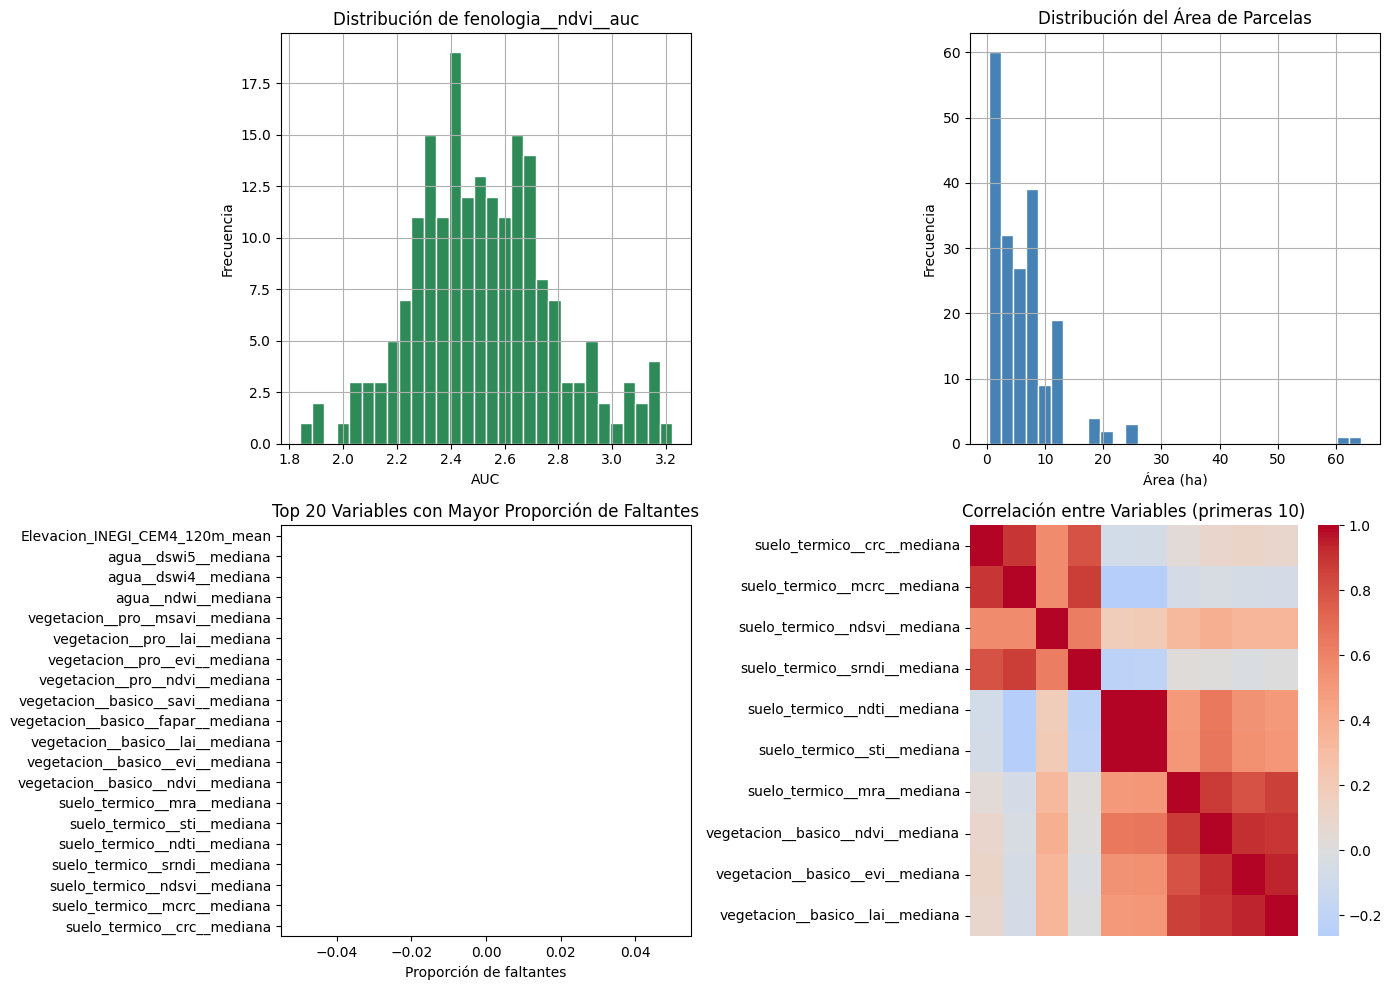

In [ ]:
# ============================================================
# 6. DIAGNÓSTICO DE CALIDAD DE LA MATRIZ INTEGRADA
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 60)
print("DIAGNÓSTICO DE CALIDAD DE LA MATRIZ INTEGRADA")
print("=" * 60)

# Proporción de valores faltantes por bloque
print("\n📊 Proporción de valores faltantes por bloque:")
for prefijo, nombre in [('suelo_termico', 'Suelo/Térmico'),
                         ('vegetacion', 'Vegetación'),
                         ('agua', 'Agua'),
                         ('fenologia', 'Fenología')]:
    cols_bloque = [c for c in X_integrado.columns if c.startswith(prefijo)]
    if cols_bloque:
        pct_faltante = X_integrado[cols_bloque].isna().mean().mean() * 100
        print(f"   {nombre}: {pct_faltante:.1f}% faltante")

# Entorno (clima/topografía)
cols_entorno_check = [c for c in X_integrado.columns if any(k in c for k in ['PREC', 'Tmax', 'Tmin', 'Elevacion', 'Pendiente'])]
if cols_entorno_check:
    pct_entorno = X_integrado[cols_entorno_check].isna().mean().mean() * 100
    print(f"   Entorno: {pct_entorno:.1f}% faltante")

# Gráfico de distribución de variables
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Distribución de AUC de NDVI (si existe)
ax = axes[0, 0]
col_auc_ndvi = [c for c in X_integrado.columns if 'ndvi' in c and 'auc' in c]
if col_auc_ndvi:
    X_integrado[col_auc_ndvi[0]].hist(bins=30, ax=ax, edgecolor='white', color='seagreen')
    ax.set_title(f'Distribución de {col_auc_ndvi[0]}')
    ax.set_xlabel('AUC')
    ax.set_ylabel('Frecuencia')

# 2. Área de parcelas
ax = axes[0, 1]
X_integrado['AREA_HA'].hist(bins=30, ax=ax, edgecolor='white', color='steelblue')
ax.set_title('Distribución del Área de Parcelas')
ax.set_xlabel('Área (ha)')
ax.set_ylabel('Frecuencia')

# 3. Proporción de faltantes por variable
ax = axes[1, 0]
faltantes = X_integrado.isna().mean().sort_values(ascending=False).head(20)
faltantes.plot(kind='barh', ax=ax, color='coral')
ax.set_title('Top 20 Variables con Mayor Proporción de Faltantes')
ax.set_xlabel('Proporción de faltantes')

# 4. Correlación entre bloques (si hay suficientes datos)
ax = axes[1, 1]
cols_numericas = X_integrado.select_dtypes(include=[np.number]).columns.tolist()
if len(cols_numericas) > 5:
    corr = X_integrado[cols_numericas].corr().iloc[:10, :10]
    sns.heatmap(corr, cmap='coolwarm', center=0, ax=ax,
                xticklabels=False, yticklabels=True)
    ax.set_title('Correlación entre Variables (primeras 10)')

plt.tight_layout()
guardar_figura(fig, '03_diagnostico_matriz_integrada.png', 'reports')
plt.show()

In [ ]:
# ============================================================
# 7. EXPORTACIÓN DE ARTEFACTOS DE LA LIBRETA 02
# ============================================================
OUT = CARPETAS['02_fenologia']

# Matriz integrada completa
guardar_csv(X_integrado.reset_index(), 'X_integrado_completo.csv', '02_fenologia')

# Variables fenológicas
if not df_fenologia.empty:
    guardar_csv(df_fenologia.reset_index(), 'variables_fenologicas.csv', '02_fenologia')

# Clima/topografía filtrado
guardar_csv(df_clima_filtrado.reset_index(), 'clima_topografia_filtrado.csv', '02_fenologia')

# Resumen de la libreta
resumen_libreta02 = {
    'version': '2.0-ingenieria-fenologica',
    'ventana_temporal': {'inicio': INICIO, 'fin': FIN},
    'n_parcelas': int(len(X_integrado)),
    'n_variables_totales': int(X_integrado.shape[1]),
    'bloques': {
        'suelo_termico': n_suelo,
        'vegetacion': n_veg,
        'agua': n_agua,
        'entorno': n_entorno,
        'clima': n_clima,
        'topografia': n_topografia,
        'fisica': n_fisica,
        'fenologia': n_fenologia,
        'area': 1
    },
    'metodo_extraccion': 'rasterstats_zonal_mean_all_touched_sin_ponderar_por_area',
    'metodo_indices_satelitales': 'mediana_temporal_del_promedio_espacial_por_captura',
    'alcance': 'retrospectivo; solo ciclo abril-octubre 2025'
}

ruta_resumen = OUT / 'resumen_libreta02.json'
with open(ruta_resumen, 'w', encoding='utf-8') as f:
    json.dump(resumen_libreta02, f, ensure_ascii=False, indent=2)
print(f"✅ Guardado: {ruta_resumen}")

# Listar archivos generados
print("\n" + "=" * 60)
print("ARCHIVOS GENERADOS EN ESTA LIBRETA")
print("=" * 60)
listar_archivos('02_fenologia')

print("\n" + "=" * 60)
print("✅ LIBRETA 02 COMPLETADA")
print("=" * 60)
print("\nArtefactos clave para el reporte:")
print("   1. X_integrado_completo.csv → Matriz de características (insumo para Libreta 03)")
print("   2. variables_fenologicas.csv → Métricas fenológicas (AUC, Delta, P90, IQR)")
print("   3. clima_topografia_filtrado.csv → Variables climáticas y topográficas")
print("   4. 03_diagnostico_matriz_integrada.png → Sección: Metodología")
print("   5. resumen_libreta02.json → Datos numéricos para el texto")
print("\n📌 Siguiente paso: Ejecutar la Libreta 03 - Validación Robusta y Ablación")

✅ Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia/X_integrado_completo.csv
✅ Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia/variables_fenologicas.csv
✅ Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia/clima_topografia_filtrado.csv
✅ Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/02_fenologia/resumen_libreta02.json

ARCHIVOS GENERADOS EN ESTA LIBRETA
📁 Carpeta '02_fenologia': 4 archivos
   • X_integrado_completo.csv (426.9 KB)
   • clima_topografia_filtrado.csv (85.0 KB)
   • resumen_libreta02.json (596.0 B)
   • variables_fenologicas.csv (288.9 KB)

✅ LIBRETA 02 COMPLETADA

Artefactos clave para el reporte:
   1. X_integrado_completo.csv → Matriz de características (insumo para Libreta 03)
   2. variables_fenologicas.csv → Métricas fenológicas (AUC, Delta, P90, IQR)
   3. clima_topografia_filtrado.csv → Variables climáticas y topográficas
   4. 03_diagnostico_matriz_integrada.png → Sección: Metodología
